# Marketing A/B Test: Conversion Analysis & Machine Learning

**A complete workflow using all eight supplied files and all 588,101 original records.**
Compare ad and public-service-announcement (PSA) conversions, validate the supplied summaries,
inspect reported logistic-regression results, and train separate predictive models on a holdout split.
No customer rows, conversions, or published model results are invented.

**Large-file support:** `marketing_ab_segmented.csv` is about 44.2 MB. The dedicated section below
reads it locally or from a Colab upload. If it is unavailable, the notebook reconstructs its six
derived columns exactly from `marketing_AB.csv`, without generating new observations. Both paths
use the same analysis. The smaller raw CSV is about 22.6 MB.

**Run:** extract the project, open this notebook in Jupyter, VS Code, or Colab, and run cells in order.
The full project includes all eight CSVs in `data/`. The GitHub-ready package excludes the large
segmented CSV. The six small report CSVs are also embedded verbatim here for portability; the raw
row-level dataset must be supplied as a file. Outputs go to `generated/` and originals stay unchanged.


## 1. Setup and file locations

Python 3.11 or 3.12 is recommended. Install the supplied requirements if necessary; the optional
install line is inactive by default. In Colab, set `USE_COLAB_UPLOAD = True` to upload files at
runtime instead of committing them to GitHub. Upload the raw CSV and, optionally, the segmented CSV.
For Google Drive, mount Drive yourself and set the explicit paths below to the mounted files.


In [3]:
# Uncomment only if the environment needs the analysis packages, then restart the kernel:
# %pip install numpy==2.3.5 pandas==3.0.1 scipy==1.18.1 scikit-learn==1.7.2 matplotlib==3.10.8
from pathlib import Path
import os, io, json, hashlib, platform, warnings
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import norm, chi2, chi2_contingency
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
    RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.exceptions import ConvergenceWarning

DATA_DIR = Path('/content')
OUTPUT_DIR = Path('generated')
DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)
RAW_PATH = Path('/content/marketing_AB.csv')
SEGMENTED_PATH = Path('/content/marketing_ab_segmented.csv')
USE_COLAB_UPLOAD = False
FORCE_REBUILD_SEGMENTED = os.environ.get('MARKETING_FORCE_REBUILD', '0') == '1'
EXPORT_LARGE_ROW_FILES = False
SEED = 42
if USE_COLAB_UPLOAD:
    from google.colab import files
    for name, content in files.upload().items():
        (DATA_DIR / Path(name).name).write_bytes(content)
plt.rcParams.update({'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
packages = {p:metadata.version(p) for p in ['numpy','pandas','scipy','scikit-learn','matplotlib']}
display(pd.Series(packages,name='installed_version').to_frame())
def save_plot(name):
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR/name,dpi=150,bbox_inches='tight')
    plt.show()

def find_file(name, explicit=None, required=False):
    if explicit is not None:
        candidate=Path(explicit).expanduser()
        if not candidate.is_file(): raise FileNotFoundError(candidate)
        return candidate
    for candidate in [DATA_DIR/name,Path(name),Path.home()/'Downloads'/name]:
        if candidate.is_file(): return candidate
    if required:
        raise FileNotFoundError(f'Place {name} in data/, set its explicit path, or enable the Colab upload cell.')
    return None

,installed_version
numpy,2.1.3
pandas,2.2.3
scipy,1.16.3
scikit-learn,1.6.1
matplotlib,3.10.0


## 2. Load all source files and verify provenance

SHA-256 identifiers record the exact supplied files. Local source files are verified before use.
Embedded report fallbacks are exact text copies of the six small supplied CSVs, not reconstructed
results. Large datasets are read from files rather than embedded in notebook JSON.


In [4]:
SOURCE_MANIFEST = [{'file': 'marketing_AB.csv', 'bytes': 22569102, 'sha256': 'c65745ab24c3cd9a20283434d2e4c5ec3d248cd64b06d199c46dd1099b5b5210', 'rows': 588101}, {'file': 'group_conversion_summary_final.csv', 'bytes': 219, 'sha256': 'b24060059c8064f2767de802b3f71d35dd31f3d4195657ce9de655e174e7ce46', 'rows': 2}, {'file': 'marketing_ab_segmented.csv', 'bytes': 44213874, 'sha256': 'bbaac50d493da723b4160eba1d3784d6de54cbe5c48f37a34f7e0e27474cb759', 'rows': 588101}, {'file': 'logistic_regression_or_table.csv', 'bytes': 4096, 'sha256': 'bca9bc620d27abe0f8e1a9a15dbd249d9bda412f829b85ab151b50efbfc677a6', 'rows': 32}, {'file': 'logistic_regression_vif.csv', 'bytes': 2170, 'sha256': 'e05a9cd4872c9e2093c8ff5dc4aa04eaa4301fde5d4ebb9205892ebd7e6a47a6', 'rows': 31}, {'file': 'logit_interaction_terms.csv', 'bytes': 1584, 'sha256': '75458edf531c08830238157e5974ca6b4e2467c779d04a0d9145f693e08b6436', 'rows': 7}, {'file': 'logit_robustness_comparison.csv', 'bytes': 1266, 'sha256': '8cb3052d1ce826aaf248635baf1a4b6b8b540ef3f5e002a49a433f2364b65713', 'rows': 4}, {'file': 'segment_conversion_summary.csv', 'bytes': 7991, 'sha256': 'bba4bf14f68f4b6b3ec0a869265ff146879db03132b9106457b32616b97b6883', 'rows': 76}]
EMBEDDED_REPORTS = {'group_conversion_summary_final.csv': 'test_group,n_total,n_converted,conversion_rate,ci_low,ci_high\r\nad,564577,14423,0.025546559636683747,0.02513821650599992,0.025961359215123686\r\npsa,23524,420,0.01785410644448223,0.016238943989596074,0.019626711612411318\r\n', 'logistic_regression_or_table.csv': 'term,odds_ratio,ci_95_lower,ci_95_upper,p_value\r\nIntercept,0.00710959804908616,0.005652188766165535,0.008942798358424354,0.0\r\n"C(test_group, Treatment(reference=""psa""))[T.ad]",1.4713076847472113,1.3297821042673312,1.6278954997585169,7.243274907982632e-14\r\n"C(most_ads_day, Treatment(reference=""Friday""))[T.Monday]",1.5861299971151666,1.4935243844784851,1.684477598018621,4.735043521628305e-51\r\n"C(most_ads_day, Treatment(reference=""Friday""))[T.Saturday]",1.0199777584203984,0.9536071680355221,1.0909677092879686,0.5644750687521354\r\n"C(most_ads_day, Treatment(reference=""Friday""))[T.Sunday]",1.2330173042077466,1.15667319074393,1.3144003722416329,1.3350564112214293e-10\r\n"C(most_ads_day, Treatment(reference=""Friday""))[T.Thursday]",1.0595362473088394,0.9911350105007164,1.1326580611799373,0.08942337389496674\r\n"C(most_ads_day, Treatment(reference=""Friday""))[T.Tuesday]",1.5420291802840014,1.4482786671120265,1.6418483865325197,9.938668291178493e-42\r\n"C(most_ads_day, Treatment(reference=""Friday""))[T.Wednesday]",1.2274584871578014,1.1502335993580703,1.3098681333396642,6.344551217009999e-10\r\n"C(most_ads_hour, Treatment(reference=0))[T.1]",0.6854633832805608,0.4937231493887786,0.951667043362484,0.024078012491598355\r\n"C(most_ads_hour, Treatment(reference=0))[T.2]",0.3441084869866958,0.2319770694952569,0.5104411874583754,1.1420734343161e-07\r\n"C(most_ads_hour, Treatment(reference=0))[T.3]",0.5685568287500046,0.3679558220866221,0.8785208661331161,0.010980074935887766\r\n"C(most_ads_hour, Treatment(reference=0))[T.4]",0.5791174350524624,0.28848887094294806,1.1625301263287466,0.1244431662590357\r\n"C(most_ads_hour, Treatment(reference=0))[T.5]",0.6157069381277139,0.33594732872421035,1.1284359220781763,0.1166382850309939\r\n"C(most_ads_hour, Treatment(reference=0))[T.6]",0.7911550826722341,0.5417082106574723,1.1554677454093256,0.2254329072496427\r\n"C(most_ads_hour, Treatment(reference=0))[T.7]",0.7794783668952199,0.5874374329559291,1.0342999788085032,0.08429753536203341\r\n"C(most_ads_hour, Treatment(reference=0))[T.8]",1.0113721869156282,0.8025947900977981,1.2744584354227628,0.9236345711259109\r\n"C(most_ads_hour, Treatment(reference=0))[T.9]",1.0323898026184342,0.8293079463392293,1.2852025707161754,0.7754692226582446\r\n"C(most_ads_hour, Treatment(reference=0))[T.10]",1.0904997110947405,0.8797419710690456,1.351748193226057,0.4291444129120615\r\n"C(most_ads_hour, Treatment(reference=0))[T.11]",1.134891386413012,0.9175753628338765,1.4036759389186346,0.24329920524200477\r\n"C(most_ads_hour, Treatment(reference=0))[T.12]",1.2168438604628398,0.9847544243703115,1.5036327272080323,0.06911324584049486\r\n"C(most_ads_hour, Treatment(reference=0))[T.13]",1.3026615033858537,1.0547309581862772,1.6088718921473018,0.014102531712073131\r\n"C(most_ads_hour, Treatment(reference=0))[T.14]",1.537013303395242,1.2453833380638002,1.8969339179427256,6.222957711529543e-05\r\n"C(most_ads_hour, Treatment(reference=0))[T.15]",1.5698911174319818,1.2721698239482309,1.937287046271055,2.6262923937663015e-05\r\n"C(most_ads_hour, Treatment(reference=0))[T.16]",1.806882165203209,1.4630527747852,2.2315142797284024,3.9441164668634946e-08\r\n"C(most_ads_hour, Treatment(reference=0))[T.17]",1.5522876919619597,1.254868422991319,1.920198990163973,5.078373241975386e-05\r\n"C(most_ads_hour, Treatment(reference=0))[T.18]",1.4436579678349903,1.165524782220236,1.7881630316974557,0.0007716748418722834\r\n"C(most_ads_hour, Treatment(reference=0))[T.19]",1.4234158180434069,1.1481626581017508,1.764656407138287,0.0012815499435017454\r\n"C(most_ads_hour, Treatment(reference=0))[T.20]",1.5877100359421885,1.2815464319297367,1.9670166413211585,2.3415568367587887e-05\r\n"C(most_ads_hour, Treatment(reference=0))[T.21]",1.592333722122263,1.2856478481658868,1.9721782183394454,2.027194486606822e-05\r\n"C(most_ads_hour, Treatment(reference=0))[T.22]",1.5164330975255835,1.2210541504723613,1.8832656507342072,0.00016538753640497872\r\n"C(most_ads_hour, Treatment(reference=0))[T.23]",1.417058379690613,1.1337576663537972,1.7711496125175996,0.0021905936831443777\r\ntotal_ads,1.0103513136076796,1.010154028993366,1.0105486367519778,0.0\r\n', 'logistic_regression_vif.csv': 'predictor,vif\r\n"C(most_ads_hour, Treatment(reference=0))[T.13]",8.831561558432615\r\n"C(most_ads_hour, Treatment(reference=0))[T.12]",8.778622102179682\r\n"C(most_ads_hour, Treatment(reference=0))[T.11]",8.614818707069826\r\n"C(most_ads_hour, Treatment(reference=0))[T.14]",8.5286991242006\r\n"C(most_ads_hour, Treatment(reference=0))[T.15]",8.382972262353029\r\n"C(most_ads_hour, Treatment(reference=0))[T.10]",7.50370763253919\r\n"C(most_ads_hour, Treatment(reference=0))[T.16]",7.28934123165713\r\n"C(most_ads_hour, Treatment(reference=0))[T.17]",6.885141450834028\r\n"C(most_ads_hour, Treatment(reference=0))[T.18]",6.4635476916662915\r\n"C(most_ads_hour, Treatment(reference=0))[T.9]",6.254123330504364\r\n"C(most_ads_hour, Treatment(reference=0))[T.19]",6.1488704093226625\r\n"C(most_ads_hour, Treatment(reference=0))[T.21]",6.088919079346904\r\n"C(most_ads_hour, Treatment(reference=0))[T.20]",5.919497455533055\r\n"C(most_ads_hour, Treatment(reference=0))[T.22]",5.5163565411703575\r\n"C(most_ads_hour, Treatment(reference=0))[T.23]",4.485527261707337\r\n"C(most_ads_hour, Treatment(reference=0))[T.8]",4.0591943941952495\r\n"C(most_ads_hour, Treatment(reference=0))[T.7]",2.134180858042842\r\n"C(most_ads_hour, Treatment(reference=0))[T.2]",1.9457518746113214\r\n"C(most_ads_hour, Treatment(reference=0))[T.1]",1.8524035766215023\r\n"C(most_ads_day, Treatment(reference=""Friday""))[T.Monday]",1.6545721877284156\r\n"C(most_ads_day, Treatment(reference=""Friday""))[T.Sunday]",1.6453320520689168\r\n"C(most_ads_day, Treatment(reference=""Friday""))[T.Thursday]",1.6306802130422822\r\n"C(most_ads_day, Treatment(reference=""Friday""))[T.Saturday]",1.6217352687885007\r\n"C(most_ads_day, Treatment(reference=""Friday""))[T.Wednesday]",1.6182900112071745\r\n"C(most_ads_day, Treatment(reference=""Friday""))[T.Tuesday]",1.5993291299006178\r\n"C(most_ads_hour, Treatment(reference=0))[T.3]",1.4773180757848345\r\n"C(most_ads_hour, Treatment(reference=0))[T.6]",1.3695775146874314\r\n"C(most_ads_hour, Treatment(reference=0))[T.5]",1.13709549745214\r\n"C(most_ads_hour, Treatment(reference=0))[T.4]",1.1291432299307278\r\ntotal_ads,1.0025932354303426\r\n"C(test_group, Treatment(reference=""psa""))[T.ad]",1.0007324746686248\r\n', 'logit_interaction_terms.csv': 'model_name,term,term_type,coefficient_log_odds,odds_ratio,ci_lower,ci_upper,p_value\r\nexposure_band_interaction,"C(test_group, Treatment(reference=""psa""))[T.ad]",baseline_ad_vs_psa_at_reference_exposure,0.22121212623720982,1.2475880486552018,0.3942618747314876,3.947822599401307,0.7066369393206682\r\nexposure_band_interaction,"C(test_group, Treatment(reference=""psa""))[T.ad]:C(total_ads_bin)[T.2–5]",interaction,-0.3605221957476911,0.6973120975678565,0.201497876135995,2.4131478243785938,0.5692342139604818\r\nexposure_band_interaction,"C(test_group, Treatment(reference=""psa""))[T.ad]:C(total_ads_bin)[T.6–10]",interaction,-0.5599672201441366,0.5712277883064866,0.16748811748808734,1.9482049892687374,0.37102160050967414\r\nexposure_band_interaction,"C(test_group, Treatment(reference=""psa""))[T.ad]:C(total_ads_bin)[T.11–20]",interaction,-0.19700759947338886,0.8211843927200055,0.24685064095479417,2.731788761976182,0.7480229648087613\r\nexposure_band_interaction,"C(test_group, Treatment(reference=""psa""))[T.ad]:C(total_ads_bin)[T.21–50]",interaction,0.07361801726296661,1.0763955624342758,0.33498247449210267,3.458770219501486,0.9016245373084456\r\nexposure_band_interaction,"C(test_group, Treatment(reference=""psa""))[T.ad]:C(total_ads_bin)[T.51–100]",interaction,0.5195446767261918,1.681261957694713,0.522430932951898,5.410555907208728,0.3836337262630918\r\nexposure_band_interaction,"C(test_group, Treatment(reference=""psa""))[T.ad]:C(total_ads_bin)[T.101+]",interaction,0.20628418910663548,1.2291024518945046,0.38213173258035454,3.9533299866307616,0.7292869089032071\r\n', 'logit_robustness_comparison.csv': 'model_name,exposure_specification,interaction_included,ad_vs_psa_or,ci_lower,ci_upper,p_value,log_likelihood,aic,bic,pseudo_r2,brier_score,roc_auc,converged,iteration_count,instability_flag,instability_note\r\noriginal_linear_exposure,linear total_ads,False,1.4713076847472113,1.3297821042673312,1.6278954997585169,7.243274907982632e-14,-63588.38462230599,127240.76924461198,127601.87817199879,0.0819813755676414,0.024575012042597853,0.8146344479160545,True,8,False,\r\nlog1p_exposure,log1p(total_ads),False,1.480847920783517,1.3377038933182763,1.6393093983222131,3.748342139497682e-14,-55846.464045892826,111756.92809178565,112118.03701917247,0.19375064475474169,0.02319233474123172,0.8574575938204645,True,8,False,\r\ncategorical_exposure_bands,verified categorical total_ads_bin,False,1.4937145673312524,1.3504624843845103,1.652162303253081,6.152147114891652e-15,-55224.530470371676,110523.06094074335,110940.59313803434,0.20272943245125985,0.022740642561029714,0.8520998197483718,True,9,False,\r\nexposure_band_interaction,verified categorical total_ads_bin,True,1.2475880486552018,0.3942618747314876,3.947822599401307,0.7066369393206682,-55208.52557684434,110503.05115368868,110988.29127486469,0.20296049336635347,0.022738967776403347,0.8523309062907701,True,9,False,\r\n', 'segment_conversion_summary.csv': 'segmentation_family,segment_label,test_group,group_sample_size,conversion_count,conversion_rate_percent,wilson_95_lower_percent,wilson_95_upper_percent,ad_minus_psa_gap_percentage_points,small_cell\r\nexposure,1,ad,54298,86,0.15838520755828944,0.12827905133113307,0.19554322448255534,0.02840253858081976,False\r\nexposure,1,psa,2308,3,0.12998266897746968,0.04421546490068187,0.38148236066363717,0.02840253858081976,False\r\nexposure,2–5,ad,115664,341,0.2948194771061004,0.26518179467479647,0.32775868918896,-0.04733791529440384,False\r\nexposure,2–5,psa,5553,19,0.34215739240050425,0.21916164313419173,0.5338103307967322,-0.04733791529440384,False\r\nexposure,6–10,ad,79537,386,0.485308724241548,0.43934550356254226,0.5360546111349586,-0.18819054369403038,False\r\nexposure,6–10,psa,3415,23,0.6734992679355783,0.4492135958795884,1.008632853598259,-0.18819054369403038,False\r\nexposure,11–20,ad,123334,1036,0.8399954594840028,0.7905697119670766,0.8924834647935722,0.02071835105026787,False\r\nexposure,11–20,psa,4150,34,0.8192771084337349,0.5868845473670923,1.1426340087188311,0.02071835105026787,False\r\nexposure,21–50,ad,125541,3660,2.915382225727053,2.823749947364266,3.0098959226836484,0.7377317959276262,False\r\nexposure,21–50,psa,5235,114,2.177650429799427,1.8159400325158084,2.6094937326220964,0.7377317959276262,False\r\nexposure,51–100,ad,44149,5135,11.631067521348163,11.335347766575053,11.933463751258126,5.856647661661168,False\r\nexposure,51–100,psa,1853,107,5.7744198596869944,4.801015896153497,6.930812784527096,5.856647661661168,False\r\nexposure,101+,ad,22054,3779,17.135213566699917,16.643629471142766,17.638244722838238,5.254025447888036,False\r\nexposure,101+,psa,1010,120,11.881188118811881,10.028675201874707,14.022566409839593,5.254025447888036,False\r\nday,Monday,ad,83571,2778,3.3241196108697992,3.204709327776525,3.447820742005494,1.0682658130399876,False\r\nday,Monday,psa,3502,79,2.2558537978298117,1.8138592544456502,2.8024778138921422,1.0682658130399876,False\r\nday,Tuesday,ad,74572,2270,3.044037976720485,2.923133496281348,3.169779932432311,1.5992495350280183,False\r\nday,Tuesday,psa,2907,42,1.4447884416924666,1.0706649985156196,1.9470692224433757,1.5992495350280183,False\r\nday,Wednesday,ad,77418,1963,2.5355860394223564,2.4271826725043257,2.648699513675535,0.9596548073306659,False\r\nday,Wednesday,psa,3490,55,1.5759312320916905,1.212787830333427,2.045558610467009,0.9596548073306659,False\r\nday,Thursday,ad,79077,1711,2.163713848527385,2.0646052463297044,2.2674698753097293,0.14066647336733373,False\r\nday,Thursday,psa,3905,79,2.023047375160051,1.6263298991739696,2.5140646531679423,0.14066647336733373,False\r\nday,Friday,ad,88805,1995,2.2464951297787286,2.151076035532389,2.3460454145572154,0.6162032549430725,False\r\nday,Friday,psa,3803,62,1.630291874835656,1.2738705843762825,2.0843322775915394,0.6162032549430725,False\r\nday,Saturday,ad,78802,1679,2.1306565823202455,2.032142491269972,2.233837538367038,0.7310764563580341,False\r\nday,Saturday,psa,2858,40,1.3995801259622114,1.0295092072522933,1.9001240385824871,0.7310764563580341,False\r\nday,Sunday,ad,82332,2027,2.4619831900111744,2.3583297726261336,2.57007247228221,0.40248662250545353,False\r\nday,Sunday,psa,3059,63,2.059496567505721,1.6130667137089687,2.6261817281835422,0.40248662250545353,False\r\nhour,0,ad,5309,102,1.9212657750988886,1.58527729674137,2.3267810703612923,1.9212657750988886,False\r\nhour,0,psa,227,0,0.0,0.0,1.6641113083928207,1.9212657750988886,False\r\nhour,1,ad,4615,62,1.3434452871072589,1.0494429532757072,1.7183822678423013,1.3434452871072589,False\r\nhour,1,psa,187,0,0.0,1.734723475976807e-16,2.012905814298656,1.3434452871072589,False\r\nhour,2,ad,5152,39,0.7569875776397516,0.5542611085270702,1.0330929533531392,0.7569875776397516,False\r\nhour,2,psa,181,0,0.0,0.0,2.0782452406527168,0.7569875776397516,False\r\nhour,3,ad,2590,27,1.0424710424710424,0.7174383839093726,1.51251513248604,-0.08112446314693522,False\r\nhour,3,psa,89,1,1.1235955056179776,0.19861832282563713,6.093246211504666,-0.08112446314693522,False\r\nhour,4,ad,694,11,1.585014409221902,0.8873109156543836,2.8157449137261876,1.585014409221902,False\r\nhour,4,psa,28,0,0.0,1.3877787807814457e-15,12.06433047658457,1.585014409221902,True\r\nhour,5,ad,742,16,2.1563342318059298,1.3315882850068639,3.4739180859269463,2.1563342318059298,False\r\nhour,5,psa,23,0,0.0,0.0,14.31166184504269,2.1563342318059298,True\r\nhour,6,ad,1985,46,2.3173803526448364,1.7418622331666955,3.077096985308386,2.3173803526448364,False\r\nhour,6,psa,83,0,0.0,0.0,4.423530964197387,2.3173803526448364,False\r\nhour,7,ad,6168,114,1.8482490272373542,1.5408618319636198,2.2155771557772286,1.0043671706972699,False\r\nhour,7,psa,237,2,0.8438818565400844,0.23172872372930092,3.0241304871767722,1.0043671706972699,False\r\nhour,8,ad,16968,337,1.9860914662894862,1.7867708645863425,2.2071472995996824,0.9238759882925212,False\r\nhour,8,psa,659,7,1.062215477996965,0.5154702822095916,2.1761927969884214,0.9238759882925212,False\r\nhour,9,ad,29802,582,1.9528890678477955,1.801867683192114,2.1162953401003723,0.8713582858178455,False\r\nhour,9,psa,1202,13,1.08153078202995,0.6331324844215452,1.8416090002408663,0.8713582858178455,False\r\nhour,10,ad,37454,818,2.18401238852993,2.0408187326251896,2.3370135047808422,0.8372110417285832,False\r\nhour,10,psa,1485,20,1.3468013468013469,0.8735227965081795,2.071146601361811,0.8372110417285832,False\r\nhour,11,ad,44149,992,2.2469365104532377,2.112790174612285,2.389392228924895,0.7913324347618258,False\r\nhour,11,psa,2061,30,1.455604075691412,1.021495993437116,2.0703374520786624,0.7913324347618258,False\r\nhour,12,ad,45238,1092,2.4138998187364606,2.276455872623544,2.5594247818190397,0.7148706925228685,False\r\nhour,12,psa,2060,35,1.6990291262135921,1.2241737606339544,2.35369112356544,0.7148706925228685,False\r\nhour,13,ad,45485,1140,2.5063207650873913,2.3666266802003575,2.654036378207424,0.847334589972184,False\r\nhour,13,psa,2170,36,1.6589861751152073,1.20072161289891,2.288100376071621,0.847334589972184,False\r\nhour,14,ad,43779,1251,2.8575344343178237,2.7055541297451375,3.0177871960514686,1.252397997720713,False\r\nhour,14,psa,1869,30,1.6051364365971108,1.1266427663701217,2.282159325233207,1.252397997720713,False\r\nhour,15,ad,42855,1279,2.9844825574612064,2.8275461251541385,3.149847037192873,0.4680711789054075,False\r\nhour,15,psa,1828,46,2.516411378555799,1.8918738096793632,3.3400996430011487,0.4680711789054075,False\r\nhour,16,ad,35963,1111,3.089286210827795,2.915408078884586,3.2731849933458843,0.2837999265385185,False\r\nhour,16,psa,1604,45,2.8054862842892767,2.1032608003616864,3.733226267805107,0.2837999265385185,False\r\nhour,17,ad,33605,959,2.853742002678173,2.681040330148823,3.037221220685754,0.8291577655125906,False\r\nhour,17,psa,1383,28,2.0245842371655822,1.4044111944333093,2.9105347166573887,0.8291577655125906,False\r\nhour,18,ad,31052,853,2.7470050238309933,2.570971211003908,2.9347287749002033,0.22930242745019092,False\r\nhour,18,psa,1271,32,2.5177025963808024,1.7889856873116248,3.5325747586007323,0.22930242745019092,False\r\nhour,19,ad,29169,782,2.6809283828722275,2.501701327729266,2.872617320777432,0.22953362378516085,False\r\nhour,19,psa,1183,29,2.4513947590870666,1.7121664481663055,3.498424937994314,0.22953362378516085,False\r\nhour,20,ad,27846,843,3.0273647920706743,2.832509214673163,3.2351786797779636,1.2632050891923086,False\r\nhour,20,psa,1077,19,1.7641597028783658,1.1322685826208745,2.738924410507584,1.2632050891923086,False\r\nhour,21,ad,28895,843,2.9174597681259735,2.7295820782335887,3.1178546130560187,0.6972932556375371,False\r\nhour,21,psa,1081,24,2.2201665124884364,1.496417954964808,3.282294952730457,0.6972932556375371,False\r\nhour,22,ad,25515,675,2.6455026455026456,2.455600306333247,2.8496619290443435,1.0097338341613151,False\r\nhour,22,psa,917,15,1.6357688113413305,0.9937661894022438,2.6812919323328814,1.0097338341613151,False\r\nhour,23,ad,19547,449,2.297027676881363,2.0961997337754683,2.516601514294665,1.0046205686422676,False\r\nhour,23,psa,619,8,1.2924071082390953,0.6563060454856675,2.529329486590587,1.0046205686422676,False\r\n'}
expected = {item['file']:item for item in SOURCE_MANIFEST}
source_log=[]
def verify_file(path,name):
    data=path.read_bytes()
    digest=hashlib.sha256(data).hexdigest()
    if digest != expected[name]['sha256']:
        raise ValueError(f'{name} differs from the original supplied file. Review the input before continuing.')
    source_log.append({'file':name,'mode':'original file','bytes':len(data),'verified':True})
    return pd.read_csv(path)
reports={}
for name,text in EMBEDDED_REPORTS.items():
    path=find_file(name)
    if path is not None:
        reports[name]=verify_file(path,name)
    else:
        assert hashlib.sha256(text.encode('utf-8')).hexdigest() == expected[name]['sha256']
        reports[name]=pd.read_csv(io.StringIO(text))
        source_log.append({'file':name,'mode':'verbatim embedded report','bytes':len(text.encode('utf-8')),'verified':True})
raw_path=find_file('marketing_AB.csv',RAW_PATH,required=True)
raw=verify_file(raw_path,'marketing_AB.csv')
display(pd.DataFrame(SOURCE_MANIFEST)[['file','rows','bytes']])
print('Original raw records:',raw.shape)


,file,rows,bytes
0,marketing_AB.csv,588101,22569102
1,group_conversion_summary_final.csv,2,219
2,marketing_ab_segmented.csv,588101,44213874
3,logistic_regression_or_table.csv,32,4096
4,logistic_regression_vif.csv,31,2170
5,logit_interaction_terms.csv,7,1584
6,logit_robustness_comparison.csv,4,1266
7,segment_conversion_summary.csv,76,7991


Original raw records: (588101, 7)


## 3. Validate the original customer records

`column_A` is an exported row identifier and `user_id` is an identifier, not a model feature.
A conversion is parsed strictly from the supplied boolean values. No missing outcomes are filled,
no employees or customers are synthesized, and no source rows are dropped or duplicated.


In [5]:
RAW_COLUMNS=['column_A','user_id','test_group','converted','total_ads','most_ads_day','most_ads_hour']
assert raw.columns.tolist()==RAW_COLUMNS
assert len(raw)==expected['marketing_AB.csv']['rows']==588101
assert raw.user_id.is_unique
assert not raw[RAW_COLUMNS].isna().any().any()
def strict_bool(series):
    converted=series.astype(str).str.lower().map({'true':True,'false':False})
    if converted.isna().any(): raise ValueError('Unexpected boolean value')
    return converted.astype(bool)
assert set(raw.test_group)=={'ad','psa'}
assert raw.total_ads.ge(1).all() and raw.total_ads.mod(1).eq(0).all()
assert raw.most_ads_hour.between(0,23).all()
quality=pd.DataFrame({'check':['records','unique user IDs','duplicate full rows','missing source cells','conversions'],
    'value':[len(raw),raw.user_id.nunique(),int(raw.duplicated().sum()),int(raw.isna().sum().sum()),int(strict_bool(raw.converted).sum())]})
display(quality)
display(raw.drop(columns=['column_A','user_id']).head())


,check,value
0,records,588101
1,unique user IDs,588101
2,duplicate full rows,0
3,missing source cells,0
4,conversions,14843


,test_group,converted,total_ads,most_ads_day,most_ads_hour
0,ad,False,130,Monday,20
1,ad,False,93,Tuesday,22
2,ad,False,21,Tuesday,18
3,ad,False,355,Tuesday,10
4,ad,False,276,Friday,14


## 4. Use the large segmented dataset without uploading it to GitHub

**Option A — supplied file:** place `marketing_ab_segmented.csv` in `data/`, beside the notebook,
or set `SEGMENTED_PATH` in section 1. Colab uploads and mounted Drive paths also work.

**Option B — GitHub-friendly reconstruction:** when the file is absent, use every original raw row
and recreate only the six derived columns. Exposure bands are **1, 2–5, 6–10, 11–20, 21–50,
51–100, 101+**. Small-cell flags use **fewer than 30 records per test group and segment** for each
segmentation family. `small_cell` is the union of the three flags. These rules were verified
against the supplied 588,101-row segmented file, including every derived value and row order.

The variable **segmented** below is used directly for all group/segment summaries and model input.
Reconstructed derived fields are not new observations. `FORCE_REBUILD_SEGMENTED = True` can be used
to exercise this route even when the original segmented file is available.


In [6]:
EXPOSURE_LABELS=['1','2–5','6–10','11–20','21–50','51–100','101+']
def build_segmented(frame):
    result=frame.copy(deep=True)
    result['converted_bool']=strict_bool(result['converted'])
    result['total_ads_bin']=pd.cut(result.total_ads,[0,1,5,10,20,50,100,np.inf],
                                    labels=EXPOSURE_LABELS,right=True).astype(str)
    for flag,feature in [('exposure_small_cell','total_ads_bin'),
                         ('day_small_cell','most_ads_day'),('hour_small_cell','most_ads_hour')]:
        counts=result.groupby(['test_group',feature],observed=True)['user_id'].transform('size')
        result[flag]=counts.lt(30)
    result['small_cell']=result[['exposure_small_cell','day_small_cell','hour_small_cell']].any(axis=1)
    return result
rebuilt=build_segmented(raw)
segmented_path=None if FORCE_REBUILD_SEGMENTED else find_file('marketing_ab_segmented.csv',SEGMENTED_PATH)
if segmented_path is not None:
    segmented=verify_file(segmented_path,'marketing_ab_segmented.csv')
    pd.testing.assert_frame_equal(segmented,rebuilt,check_dtype=False)
    segmented_mode='loaded original segmented file; all values verified against raw-derived reconstruction'
else:
    segmented=rebuilt
    segmented_mode='reconstructed all original rows and six derived columns from raw data'
    source_log.append({'file':'marketing_ab_segmented.csv','mode':'exact value reconstruction',
                       'bytes':None,'verified':True})
assert segmented.columns.tolist()==RAW_COLUMNS+['converted_bool','total_ads_bin',
    'exposure_small_cell','day_small_cell','hour_small_cell','small_cell']
assert len(segmented)==len(raw) and segmented.user_id.tolist()==raw.user_id.tolist()
print(segmented_mode)
display(segmented[['user_id','test_group','converted_bool','total_ads','total_ads_bin','small_cell']].head())
display(segmented.groupby(['most_ads_hour','test_group']).agg(
    records=('user_id','size'),flag=('hour_small_cell','max')).query('flag'))
print('Small-cell rows:',int(segmented.small_cell.sum()))
if EXPORT_LARGE_ROW_FILES:
    segmented.to_csv(OUTPUT_DIR/'marketing_ab_segmented.csv',index=False)
    print('Saved a large derived CSV locally; keep it out of ordinary GitHub browser uploads.')


loaded original segmented file; all values verified against raw-derived reconstruction


,user_id,test_group,converted_bool,total_ads,total_ads_bin,small_cell
0,1069124,ad,False,130,101+,False
1,1119715,ad,False,93,51–100,False
2,1144181,ad,False,21,21–50,False
3,1435133,ad,False,355,101+,False
4,1015700,ad,False,276,101+,False


,,records,flag
most_ads_hour,test_group,,
4,psa,28,True
5,psa,23,True


Small-cell rows: 51


## 5. Recalculate overall conversion rates and confidence intervals

Compare actual conversion counts by test group. Wilson 95% intervals are calculated from those
counts, then checked against `group_conversion_summary_final.csv`. An interval for each group
is not itself an interval for their difference; the difference is evaluated separately below.


,test_group,n_total,n_converted,conversion_rate,ci_low,ci_high
0,ad,564577,14423,0.025547,0.025138,0.025961
1,psa,23524,420,0.017854,0.016239,0.019627


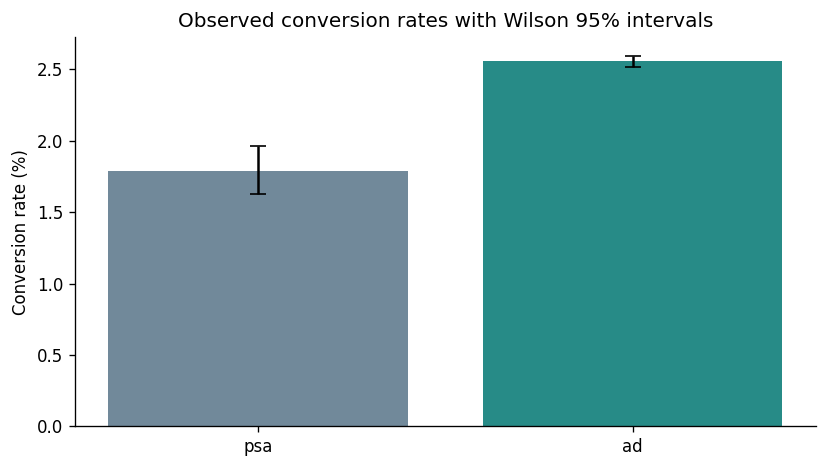

In [7]:
Z=norm.ppf(0.975)
def wilson(successes,total):
    p=np.asarray(successes,dtype=float)/np.asarray(total,dtype=float)
    n=np.asarray(total,dtype=float)
    center=(p+Z**2/(2*n))/(1+Z**2/n)
    half=Z*np.sqrt(p*(1-p)/n+Z**2/(4*n**2))/(1+Z**2/n)
    return np.clip(center-half,0,1),np.clip(center+half,0,1)
overall=(segmented.groupby('test_group').converted_bool.agg(n_total='size',n_converted='sum').reset_index())
overall['conversion_rate']=overall.n_converted/overall.n_total
overall['ci_low'],overall['ci_high']=wilson(overall.n_converted,overall.n_total)
saved=reports['group_conversion_summary_final.csv']
check=overall.merge(saved,on='test_group',suffixes=('_new','_saved'),validate='one_to_one')
assert len(check)==len(saved)==2
for field in ['n_total','n_converted','conversion_rate','ci_low','ci_high']:
    assert np.allclose(check[field+'_new'],check[field+'_saved'],rtol=1e-9,atol=1e-12),field
display(overall)
ordered=overall.set_index('test_group').loc[['psa','ad']]
plt.figure(figsize=(7,4))
plt.bar(ordered.index,100*ordered.conversion_rate,color=['#71899a','#278b87'])
plt.errorbar(np.arange(2),100*ordered.conversion_rate,
    yerr=100*np.vstack([ordered.conversion_rate-ordered.ci_low,ordered.ci_high-ordered.conversion_rate]),
    fmt='none',color='black',capsize=5)
plt.ylabel('Conversion rate (%)')
plt.title('Observed conversion rates with Wilson 95% intervals')
save_plot('overall_conversion_rates.png')


## 6. Quantify the ad-versus-PSA difference

Calculate absolute difference, relative lift, a Newcombe interval for the difference (using
the Wilson intervals), and a two-sided Pearson chi-square test without continuity correction.
The supplied file labels this an A/B test, but allocation rules, experiment duration, and
randomization checks are unavailable. Report the observed contrast; causal interpretation
requires valid randomization, consistent measurement, and appropriate experiment design.
No assumed 50/50 allocation is used for a sample-ratio-mismatch test.


In [8]:
arm=overall.set_index('test_group')
ad,psa=arm.loc['ad'],arm.loc['psa']
gap=float(ad.conversion_rate-psa.conversion_rate)
relative_lift=float(ad.conversion_rate/psa.conversion_rate-1)
gap_low=gap-np.sqrt((ad.conversion_rate-ad.ci_low)**2+(psa.ci_high-psa.conversion_rate)**2)
gap_high=gap+np.sqrt((ad.ci_high-ad.conversion_rate)**2+(psa.conversion_rate-psa.ci_low)**2)
contingency=np.array([[ad.n_converted,ad.n_total-ad.n_converted],
                      [psa.n_converted,psa.n_total-psa.n_converted]],dtype=int)
chi_stat,p_value,dof,expected_counts=chi2_contingency(contingency,correction=False)
effect=pd.DataFrame([{'comparison':'ad minus psa','absolute_gap_percentage_points':100*gap,
    'newcombe_95_lower_pp':100*gap_low,'newcombe_95_upper_pp':100*gap_high,
    'relative_lift_percent':100*relative_lift,'chi_square':chi_stat,'two_sided_p_value':p_value}])
display(effect)
print('Minimum expected contingency count:',expected_counts.min())
print('User records:',len(segmented),'| Overall conversions:',int(segmented.converted_bool.sum()))


,comparison,absolute_gap_percentage_points,newcombe_95_lower_pp,newcombe_95_upper_pp,relative_lift_percent,chi_square,two_sided_p_value
0,ad minus psa,0.769245,0.587342,0.936003,43.085064,54.318052,1.705281e-13


Minimum expected contingency count: 593.7189904455187
User records: 588101 | Overall conversions: 14843


## 7. Use the segmented data: exposure, day, and hour

Recreate all 76 rows of `segment_conversion_summary.csv` from **segmented**, including group
counts, conversion rates, Wilson intervals, ad-minus-PSA gaps, and small-cell flags. The PSA
groups at hours 4 and 5 have only 28 and 23 records and no observed conversions; absence of
observed conversions does not establish a true zero conversion probability.

Exposure and timing summaries can reflect post-assignment behavior. Treat these as exploratory
associations rather than automatically interpreting subgroup differences as treatment effects.


,segment_label,test_group,group_sample_size,conversion_count,segmentation_family,conversion_rate_percent,wilson_95_lower_percent,wilson_95_upper_percent,ad_minus_psa_gap_percentage_points,small_cell
0,1,ad,54298,86,exposure,0.158385,0.128279,0.195543,0.028403,False
1,1,psa,2308,3,exposure,0.129983,0.044215,0.381482,0.028403,False
2,101+,ad,22054,3779,exposure,17.135214,16.643629,17.638245,5.254025,False
3,101+,psa,1010,120,exposure,11.881188,10.028675,14.022566,5.254025,False
4,11–20,ad,123334,1036,exposure,0.839995,0.790570,0.892483,0.020718,False
5,11–20,psa,4150,34,exposure,0.819277,0.586885,1.142634,0.020718,False
6,21–50,ad,125541,3660,exposure,2.915382,2.823750,3.009896,0.737732,False
7,21–50,psa,5235,114,exposure,2.177650,1.815940,2.609494,0.737732,False
8,2–5,ad,115664,341,exposure,0.294819,0.265182,0.327759,-0.047338,False
9,2–5,psa,5553,19,exposure,0.342157,0.219162,0.533810,-0.047338,False


,segment_label,test_group,group_sample_size,conversion_count,segmentation_family,conversion_rate_percent,wilson_95_lower_percent,wilson_95_upper_percent,ad_minus_psa_gap_percentage_points,small_cell
37,4,psa,28,0,hour,0.0,1.387779e-15,12.064330,1.585014,True
39,5,psa,23,0,hour,0.0,0.000000e+00,14.311662,2.156334,True


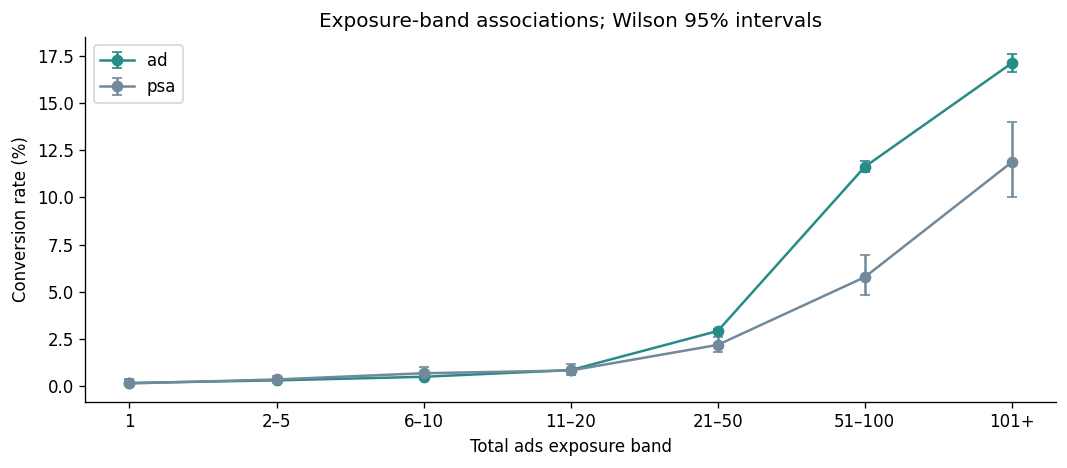

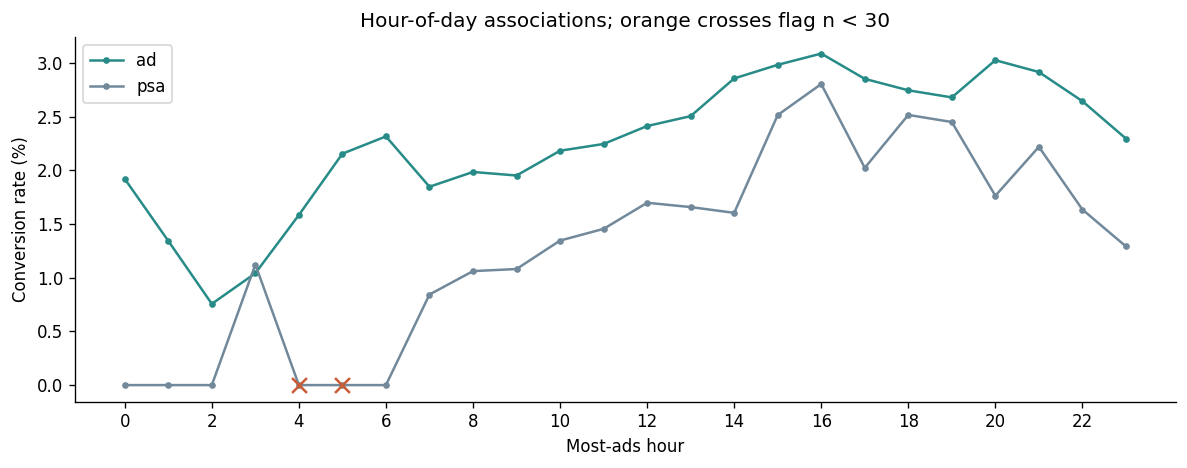

In [9]:
segment_frames=[]
for family,feature in [('exposure','total_ads_bin'),('day','most_ads_day'),('hour','most_ads_hour')]:
    group=(segmented.groupby([feature,'test_group'],observed=True).converted_bool
           .agg(group_sample_size='size',conversion_count='sum').reset_index())
    group=group.rename(columns={feature:'segment_label'})
    group['segment_label']=group.segment_label.astype(str)
    group['segmentation_family']=family
    group['conversion_rate_percent']=100*group.conversion_count/group.group_sample_size
    lo,hi=wilson(group.conversion_count,group.group_sample_size)
    group['wilson_95_lower_percent'],group['wilson_95_upper_percent']=100*lo,100*hi
    pivot=group.pivot(index='segment_label',columns='test_group',values='conversion_rate_percent')
    group['ad_minus_psa_gap_percentage_points']=group.segment_label.map(pivot.ad-pivot.psa)
    group['small_cell']=group.group_sample_size.lt(30)
    segment_frames.append(group)
segments=pd.concat(segment_frames,ignore_index=True)
saved_segments=reports['segment_conversion_summary.csv'].copy()
saved_segments['segment_label']=saved_segments.segment_label.astype(str)
keys=['segmentation_family','segment_label','test_group']
comparison=segments.merge(saved_segments,on=keys,suffixes=('_new','_saved'),validate='one_to_one')
assert len(comparison)==len(segments)==len(saved_segments)==76
for field in ['group_sample_size','conversion_count','conversion_rate_percent',
              'wilson_95_lower_percent','wilson_95_upper_percent','ad_minus_psa_gap_percentage_points']:
    assert np.allclose(comparison[field+'_new'],comparison[field+'_saved'],rtol=1e-8,atol=1e-10),field
assert np.array_equal(comparison.small_cell_new,comparison.small_cell_saved)
display(segments[segments.segmentation_family.eq('exposure')])
display(segments[segments.small_cell])
exp=segments[segments.segmentation_family.eq('exposure')]
plt.figure(figsize=(9,4))
for label,color in [('ad','#278b87'),('psa','#71899a')]:
    values=exp[exp.test_group.eq(label)].set_index('segment_label').loc[EXPOSURE_LABELS]
    plt.errorbar(EXPOSURE_LABELS,values.conversion_rate_percent,
        yerr=np.vstack([values.conversion_rate_percent-values.wilson_95_lower_percent,
                         values.wilson_95_upper_percent-values.conversion_rate_percent]),
        marker='o',capsize=3,label=label,color=color)
plt.xlabel('Total ads exposure band')
plt.ylabel('Conversion rate (%)')
plt.title('Exposure-band associations; Wilson 95% intervals')
plt.legend()
save_plot('exposure_band_conversion_rates.png')
hour=segments[segments.segmentation_family.eq('hour')].copy()
hour['hour']=hour.segment_label.astype(int)
plt.figure(figsize=(10,4))
for label,color in [('ad','#278b87'),('psa','#71899a')]:
    values=hour[hour.test_group.eq(label)].sort_values('hour')
    plt.plot(values.hour,values.conversion_rate_percent,marker='.',label=label,color=color)
    sparse=values[values.small_cell]
    plt.scatter(sparse.hour,sparse.conversion_rate_percent,marker='x',s=80,color='#c95b35',zorder=5)
plt.xlabel('Most-ads hour')
plt.ylabel('Conversion rate (%)')
plt.title('Hour-of-day associations; orange crosses flag n < 30')
plt.xticks(range(0,24,2))
plt.legend()
save_plot('hour_conversion_rates.png')


## 8. Inspect the supplied logistic-regression odds ratios and VIF

These tables are **original supplied model outputs**, not results silently refitted by this
notebook. The main model's adjusted ad-versus-PSA odds ratio is about 1.471 with a reported
95% interval of 1.330–1.628. Odds ratios are not risk ratios or percentage-point changes.
The covariates include exposure and timing, so adjustment does not automatically recover a
causal advertising effect. VIF describes the specified design columns and their reference
coding; it is not a test of causal validity or out-of-sample prediction.


In [10]:
odds=reports['logistic_regression_or_table.csv'].copy()
vif=reports['logistic_regression_vif.csv'].copy()
robustness=reports['logit_robustness_comparison.csv'].copy()
interactions=reports['logit_interaction_terms.csv'].copy()
assert odds.term.is_unique and vif.predictor.is_unique
assert odds.odds_ratio.gt(0).all() and odds.p_value.between(0,1).all()
assert odds.ci_95_lower.le(odds.odds_ratio).all() and odds.ci_95_upper.ge(odds.odds_ratio).all()
ad_term=odds[odds.term.str.contains('C(test_group',regex=False)]
assert len(ad_term)==1
linear=robustness.set_index('model_name').loc['original_linear_exposure']
assert np.allclose(ad_term.odds_ratio.iloc[0],linear.ad_vs_psa_or)
assert np.allclose(ad_term.ci_95_lower.iloc[0],linear.ci_lower)
assert np.allclose(ad_term.ci_95_upper.iloc[0],linear.ci_upper)
display(ad_term)
display(odds)
display(vif.sort_values('vif',ascending=False).head(10))
print('VIF > 5:',int(vif.vif.gt(5).sum()),'of',len(vif),'design columns')
print('VIF maximum:',vif.vif.max())


,term,odds_ratio,ci_95_lower,ci_95_upper,p_value
1,"C(test_group, Treatment(reference=""psa""))[T.ad]",1.471308,1.329782,1.627895,7.243275e-14


,term,odds_ratio,ci_95_lower,ci_95_upper,p_value
0,Intercept,0.007110,0.005652,0.008943,0.000000e+00
1,"C(test_group, Treatment(reference=""psa""))[T.ad]",1.471308,1.329782,1.627895,7.243275e-14
2,"C(most_ads_day, Treatment(reference=""Friday""))...",1.586130,1.493524,1.684478,4.735044e-51
3,"C(most_ads_day, Treatment(reference=""Friday""))...",1.019978,0.953607,1.090968,5.644751e-01
4,"C(most_ads_day, Treatment(reference=""Friday""))...",1.233017,1.156673,1.314400,1.335056e-10
5,"C(most_ads_day, Treatment(reference=""Friday""))...",1.059536,0.991135,1.132658,8.942337e-02
6,"C(most_ads_day, Treatment(reference=""Friday""))...",1.542029,1.448279,1.641848,9.938668e-42
7,"C(most_ads_day, Treatment(reference=""Friday""))...",1.227458,1.150234,1.309868,6.344551e-10
8,"C(most_ads_hour, Treatment(reference=0))[T.1]",0.685463,0.493723,0.951667,2.407801e-02
9,"C(most_ads_hour, Treatment(reference=0))[T.2]",0.344108,0.231977,0.510441,1.142073e-07


,predictor,vif
0,"C(most_ads_hour, Treatment(reference=0))[T.13]",8.831562
1,"C(most_ads_hour, Treatment(reference=0))[T.12]",8.778622
2,"C(most_ads_hour, Treatment(reference=0))[T.11]",8.614819
3,"C(most_ads_hour, Treatment(reference=0))[T.14]",8.528699
4,"C(most_ads_hour, Treatment(reference=0))[T.15]",8.382972
5,"C(most_ads_hour, Treatment(reference=0))[T.10]",7.503708
6,"C(most_ads_hour, Treatment(reference=0))[T.16]",7.289341
7,"C(most_ads_hour, Treatment(reference=0))[T.17]",6.885141
8,"C(most_ads_hour, Treatment(reference=0))[T.18]",6.463548
9,"C(most_ads_hour, Treatment(reference=0))[T.9]",6.254123


VIF > 5: 14 of 31 design columns
VIF maximum: 8.831561558432615


## 9. Compare supplied robustness and interaction results

Main-effect odds ratios from the three noninteraction exposure specifications can be compared
as adjusted associations. The interaction model's main ad coefficient applies only to the
reference exposure band, not to all users. Individual interaction odds ratios are multipliers
relative to that reference. Their intervals cannot be multiplied together to obtain a valid
confidence interval for a combined band-specific ad effect without coefficient covariance.

The likelihood-ratio calculation below uses the **supplied** log likelihoods and parameter
counts recovered from AIC for the two nested exposure-band models. It is not a newly refitted
likelihood. A joint interaction test and individual Wald tests answer different questions.
Saved Brier and ROC-AUC values have no documented holdout split in these CSVs and must not be
presented as the new holdout evaluation in section 10.


,model_name,exposure_specification,interaction_included,ad_vs_psa_or,ci_lower,ci_upper,p_value,log_likelihood,aic,bic,pseudo_r2,brier_score,roc_auc,converged,iteration_count,instability_flag,instability_note
0,original_linear_exposure,linear total_ads,False,1.471308,1.329782,1.627895,7.243275e-14,-63588.384622,127240.769245,127601.878172,0.081981,0.024575,0.814634,True,8,False,NaN
1,log1p_exposure,log1p(total_ads),False,1.480848,1.337704,1.639309,3.748342e-14,-55846.464046,111756.928092,112118.037019,0.193751,0.023192,0.857458,True,8,False,NaN
2,categorical_exposure_bands,verified categorical total_ads_bin,False,1.493715,1.350462,1.652162,6.152147e-15,-55224.530470,110523.060941,110940.593138,0.202729,0.022741,0.852100,True,9,False,NaN
3,exposure_band_interaction,verified categorical total_ads_bin,True,1.247588,0.394262,3.947823,7.066369e-01,-55208.525577,110503.051154,110988.291275,0.202960,0.022739,0.852331,True,9,False,NaN


,model_name,term,term_type,coefficient_log_odds,odds_ratio,ci_lower,ci_upper,p_value
0,exposure_band_interaction,"C(test_group, Treatment(reference=""psa""))[T.ad]",baseline_ad_vs_psa_at_reference_exposure,0.221212,1.247588,0.394262,3.947823,0.706637
1,exposure_band_interaction,"C(test_group, Treatment(reference=""psa""))[T.ad...",interaction,-0.360522,0.697312,0.201498,2.413148,0.569234
2,exposure_band_interaction,"C(test_group, Treatment(reference=""psa""))[T.ad...",interaction,-0.559967,0.571228,0.167488,1.948205,0.371022
3,exposure_band_interaction,"C(test_group, Treatment(reference=""psa""))[T.ad...",interaction,-0.197008,0.821184,0.246851,2.731789,0.748023
4,exposure_band_interaction,"C(test_group, Treatment(reference=""psa""))[T.ad...",interaction,0.073618,1.076396,0.334982,3.458770,0.901625
5,exposure_band_interaction,"C(test_group, Treatment(reference=""psa""))[T.ad...",interaction,0.519545,1.681262,0.522431,5.410556,0.383634
6,exposure_band_interaction,"C(test_group, Treatment(reference=""psa""))[T.ad...",interaction,0.206284,1.229102,0.382132,3.953330,0.729287


,model_name,converged,instability_flag,iteration_count
0,original_linear_exposure,True,False,8
1,log1p_exposure,True,False,8
2,categorical_exposure_bands,True,False,9
3,exposure_band_interaction,True,False,9


,comparison,source_likelihood_ratio,df,p_value
0,categorical bands vs bands with group interact...,32.009787,6,0.000016


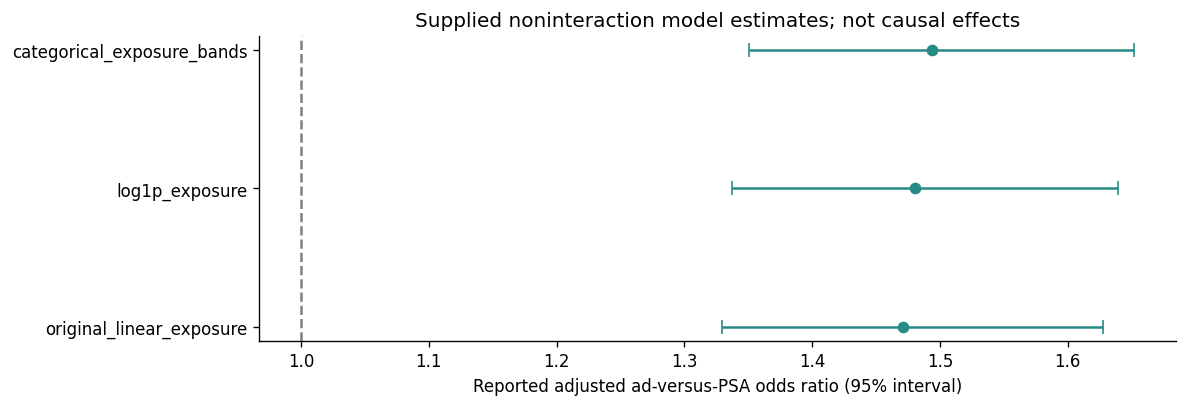

In [11]:
display(robustness)
assert np.allclose(np.exp(interactions.coefficient_log_odds),interactions.odds_ratio)
display(interactions)
source_model_check=robustness[['model_name','converged','instability_flag','iteration_count']]
display(source_model_check)
base=robustness.set_index('model_name').loc['categorical_exposure_bands']
expanded=robustness.set_index('model_name').loc['exposure_band_interaction']
base_k=(base.aic+2*base.log_likelihood)/2
expanded_k=(expanded.aic+2*expanded.log_likelihood)/2
df_difference=int(round(expanded_k-base_k))
lr_statistic=2*(expanded.log_likelihood-base.log_likelihood)
assert df_difference==6 and lr_statistic>=0
interaction_test=pd.DataFrame([{'comparison':'categorical bands vs bands with group interactions',
    'source_likelihood_ratio':lr_statistic,'df':df_difference,'p_value':chi2.sf(lr_statistic,df_difference)}])
display(interaction_test)
forest=robustness[~robustness.interaction_included].copy()
plt.figure(figsize=(10,3.5))
plt.errorbar(forest.ad_vs_psa_or,np.arange(len(forest)),
    xerr=np.vstack([forest.ad_vs_psa_or-forest.ci_lower,forest.ci_upper-forest.ad_vs_psa_or]),
    fmt='o',capsize=4,color='#278b87')
plt.yticks(np.arange(len(forest)),forest.model_name)
plt.axvline(1,color='grey',linestyle='--')
plt.xlabel('Reported adjusted ad-versus-PSA odds ratio (95% interval)')
plt.title('Supplied noninteraction model estimates; not causal effects')
save_plot('reported_adjusted_odds_ratios.png')


## 10. Train fresh predictive models using the segmented data

This section actually uses **segmented** as row-level model input. It does not train on
summary tables. Compare a prevalence baseline, a group-only logistic model, and a contextual
logistic model using group, log1p(total_ads), most-ads day and hour. These are newly fitted
regularized classifiers, distinct from the supplied inferential odds-ratio models.

Use all original rows in an 80/20 split stratified jointly by group and conversion. Fit encoders
and scaling on training rows only. There is no oversampling, class weighting, threshold tuning,
or model selection using test labels. Identifiers, converted, converted_bool, and derived
small-cell flags never enter the feature matrix. The majority class is nonconversion, so
accuracy alone would be misleading; report ROC-AUC, average precision, and Brier score.

Exposure/timing availability before conversion is not documented. The contextual model is a
retrospective classification exercise, not a validated pre-exposure targeting policy or a
causal uplift model. The supplied data has no timestamps to support a temporal test split.


Trained: Prevalence baseline
Trained: Group-only logistic
Trained: Contextual logistic


,model,holdout_rows,roc_auc,average_precision,brier_score,accuracy,precision_at_0_5,recall_at_0_5,f1_at_0_5,true_negative,false_positive,false_negative,true_positive
0,Prevalence baseline,117621,0.500000,0.025242,0.024605,0.974758,0.000000,0.000000,0.000,114652,0,2969,0
1,Group-only logistic,117621,0.506006,0.025541,0.024603,0.974758,0.000000,0.000000,0.000,114652,0,2969,0
2,Contextual logistic,117621,0.853455,0.137849,0.023247,0.974010,0.139344,0.005726,0.011,114547,105,2952,17


Training rows: 470480 | Holdout rows: 117621 | Holdout conversion prevalence: 2.524%


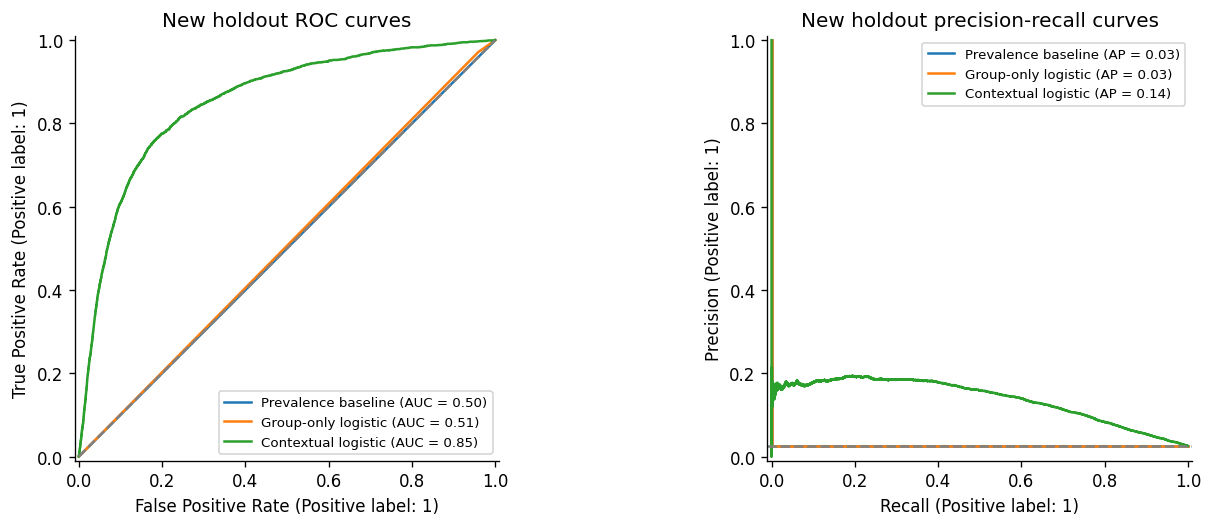

In [12]:
y=segmented.converted_bool.astype(int)
features=segmented[['test_group','most_ads_day','most_ads_hour']].copy()
features['most_ads_hour']=features.most_ads_hour.astype(str)
features['log1p_total_ads']=np.log1p(segmented.total_ads)
strata=segmented.test_group.astype(str)+'_'+y.astype(str)
train_idx,test_idx=train_test_split(np.arange(len(segmented)),test_size=0.2,
                                  random_state=SEED,stratify=strata)
X_train,X_test=features.iloc[train_idx],features.iloc[test_idx]
y_train,y_test=y.iloc[train_idx],y.iloc[test_idx]
assert set(train_idx).isdisjoint(test_idx)
def logistic_pipeline(contextual=False):
    categories=['test_group','most_ads_day','most_ads_hour'] if contextual else ['test_group']
    transformations=[('categorical',OneHotEncoder(handle_unknown='ignore'),categories)]
    if contextual:
        transformations.append(('numeric',StandardScaler(),['log1p_total_ads']))
    return Pipeline([('preprocess',ColumnTransformer(transformations,sparse_threshold=1.0)),
                     ('classifier',LogisticRegression(C=1.0,max_iter=500,tol=1e-6,solver='lbfgs',random_state=SEED))])
candidates={'Prevalence baseline':DummyClassifier(strategy='prior'),
            'Group-only logistic':logistic_pipeline(False),
            'Contextual logistic':logistic_pipeline(True)}
models,probabilities,metric_rows={}, {}, []
for name,model in candidates.items():
    with warnings.catch_warnings():
        warnings.simplefilter('error',ConvergenceWarning)
        model.fit(X_train,y_train)
    p=model.predict_proba(X_test)[:,1]
    predicted=(p>=0.5).astype(int)
    tn,fp,fn,tp=confusion_matrix(y_test,predicted,labels=[0,1]).ravel()
    models[name],probabilities[name]=model,p
    metric_rows.append({'model':name,'holdout_rows':len(y_test),
        'roc_auc':roc_auc_score(y_test,p),'average_precision':average_precision_score(y_test,p),
        'brier_score':brier_score_loss(y_test,p),'accuracy':accuracy_score(y_test,predicted),
        'precision_at_0_5':precision_score(y_test,predicted,zero_division=0),
        'recall_at_0_5':recall_score(y_test,predicted,zero_division=0),
        'f1_at_0_5':f1_score(y_test,predicted,zero_division=0),
        'true_negative':int(tn),'false_positive':int(fp),'false_negative':int(fn),'true_positive':int(tp)})
    print('Trained:',name)
new_metrics=pd.DataFrame(metric_rows)
display(new_metrics)
print('Training rows:',len(train_idx),'| Holdout rows:',len(test_idx),
      '| Holdout conversion prevalence:',f'{y_test.mean():.3%}')
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for name,p in probabilities.items():
    RocCurveDisplay.from_predictions(y_test,p,name=name,ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test,p,name=name,ax=axes[1])
axes[0].plot([0,1],[0,1],'--',color='grey')
axes[1].axhline(y_test.mean(),linestyle='--',color='grey')
axes[0].set_title('New holdout ROC curves')
axes[1].set_title('New holdout precision-recall curves')
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
save_plot('new_holdout_model_curves.png')


## 11. Export results, record reproducibility, and summarize

Only compact summaries and charts are exported by default. Setting `EXPORT_LARGE_ROW_FILES`
also writes local row-level files; those outputs are deliberately excluded by `.gitignore`.
SHA-256 checks at the end ensure that original inputs were not changed. The reconstruction
route records that it used derived fields rather than falsely claiming it loaded a missing file.


In [13]:
export_tables={'source_usage.csv':pd.DataFrame(source_log),'data_quality.csv':quality,
    'group_conversion_recomputed.csv':overall,'ad_psa_effect.csv':effect,
    'segment_conversion_recomputed.csv':segments,'source_interaction_likelihood_test.csv':interaction_test,
    'new_holdout_model_results.csv':new_metrics}
for name,frame in export_tables.items(): frame.to_csv(OUTPUT_DIR/name,index=False)
split_fingerprint=hashlib.sha256(np.asarray(train_idx,dtype='<i8').tobytes()+
                                 np.asarray(test_idx,dtype='<i8').tobytes()).hexdigest()
run_manifest={'source_files':SOURCE_MANIFEST,'python':platform.python_version(),'packages':packages,
    'seed':SEED,'segmented_mode':segmented_mode,'source_rows':len(segmented),
    'training_rows':len(train_idx),'holdout_rows':len(test_idx),
    'split_fingerprint_sha256':split_fingerprint,'small_cell_threshold':30,
    'exposure_labels':EXPOSURE_LABELS,'original_source_rows_modified':False,
    'saved_logistic_tables_refitted':False,'new_predictive_models_trained':True,
    'predictive_models_use_post_assignment_information':True}
(OUTPUT_DIR/'run_manifest.json').write_text(json.dumps(run_manifest,indent=2),encoding='utf-8')
if EXPORT_LARGE_ROW_FILES:
    predictions=pd.DataFrame({'user_id':segmented.user_id.iloc[test_idx].to_numpy(),
                              'converted':y_test.to_numpy()})
    for name,p in probabilities.items(): predictions[name+'_probability']=p
    predictions.to_csv(OUTPUT_DIR/'holdout_predictions.csv',index=False)
assert len(source_log)==8
for record in source_log:
    if record['mode']=='original file':
        path=raw_path if record['file']=='marketing_AB.csv' else (
            segmented_path if record['file']=='marketing_ab_segmented.csv' else find_file(record['file']))
        assert hashlib.sha256(path.read_bytes()).hexdigest()==expected[record['file']]['sha256']
conclusion=(f'Ad conversion {ad.conversion_rate:.3%}; PSA conversion {psa.conversion_rate:.3%}. '
    f'Observed difference {100*gap:.3f} percentage points '
    f'(Newcombe 95% interval {100*gap_low:.3f} to {100*gap_high:.3f}); '
    f'relative lift {100*relative_lift:.1f}%. '
    'Randomization validity and a pre-conversion feature cutoff remain necessary for causal or targeting claims.')
display(Markdown('### Results grounded in the supplied data\n'+conclusion))
(OUTPUT_DIR/'analysis_conclusion.txt').write_text(conclusion+'\n',encoding='utf-8')
display(pd.DataFrame(source_log)[['file','mode','verified']])
print('All eight inputs accounted for. Original files unchanged. Large segmented data was used in section 4 onward.')


### Results grounded in the supplied data
Ad conversion 2.555%; PSA conversion 1.785%. Observed difference 0.769 percentage points (Newcombe 95% interval 0.587 to 0.936); relative lift 43.1%. Randomization validity and a pre-conversion feature cutoff remain necessary for causal or targeting claims.

,file,mode,verified
0,group_conversion_summary_final.csv,original file,True
1,logistic_regression_or_table.csv,original file,True
2,logistic_regression_vif.csv,original file,True
3,logit_interaction_terms.csv,original file,True
4,logit_robustness_comparison.csv,original file,True
5,segment_conversion_summary.csv,original file,True
6,marketing_AB.csv,original file,True
7,marketing_ab_segmented.csv,original file,True


All eight inputs accounted for. Original files unchanged. Large segmented data was used in section 4 onward.


## 12. Source-file coverage and interpretation limits

| Supplied file | Role in this notebook |
| --- | --- |
| marketing_AB.csv | All original observations; source for verified segmented reconstruction |
| marketing_ab_segmented.csv | Direct local loading, or exact reconstruction of derived fields; used for analysis and model inputs |
| group_conversion_summary_final.csv | Verified against recomputed counts, rates and Wilson intervals |
| segment_conversion_summary.csv | All 76 summary rows independently recalculated from segmented data |
| logistic_regression_or_table.csv | Original adjusted odds ratios, intervals and p-values; checked against robustness export |
| logistic_regression_vif.csv | Original design-column multicollinearity diagnostic |
| logit_interaction_terms.csv | Original interaction coefficients and odds multipliers; exponential consistency checked |
| logit_robustness_comparison.csv | Supplied exposure specifications, fit statistics, interactions and convergence reports |

**Limits:** experiment allocation and duration are undocumented; conversion dates and an attribution window
are unavailable; exploratory segment comparisons involve multiplicity and small cells; post-assignment
exposure and timing may affect adjusted associations. Original inference tables are retained as supplied,
while fresh predictive holdout results are labeled separately. The new models are not a replay of the
original fitting process. No revenue, advertising costs, realized ROI, or business savings are inferred.

**GitHub:** commit this clean notebook and the smaller input files. Keep the segmented CSV local, in Drive,
or in external dataset storage, or use the verified reconstruction. Never replace it with sampled or
fabricated rows. The full project archive contains all eight originals; the GitHub-ready archive omits
only the large segmented CSV. No API key or paid AI service is required.

**Method references:** [Wilson score interval](https://www.itl.nist.gov/div898/handbook/prc/section2/prc241.htm),
[SciPy Pearson chi-square test](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.contingency.chi2_contingency.html),
[scikit-learn logistic regression](https://scikit-learn.org/1.7/modules/generated/sklearn.linear_model.LogisticRegression.html),
[GitHub browser upload limits](https://docs.github.com/en/repositories/working-with-files/managing-files/adding-a-file-to-a-repository).
